# Urban Infrastructure Failed Risk

## 1. Dataset Exploration

# pandas to load and analyse our dataset
# numpy to perform numerical operations
# matplotlib to create graphs and histograms

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path




In [2]:
df = pd.read_csv("../data/urbandata.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
df.head()

,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,inspection_season,inspection_window,moisture_stress,failure
0,5,31.762605,12.891996,4.711064,71.480592,9.429642,5.177088,2.9944,summer,afternoon,0.06,1
1,7,30.770158,11.835563,3.315888,60.300892,8.655641,4.927622,2.6808,spring,morning,0.01,0
2,6,31.591296,11.738267,2.425562,56.367965,9.017137,4.910945,2.5294,autumn,night,0.02,0
3,5,30.834649,11.622881,2.164486,53.135138,8.864650,4.949554,2.4810,autumn,afternoon,0.02,1
4,2,33.315981,12.616065,4.557082,77.482269,9.549344,5.047689,3.0460,summer,morning,0.07,1


In [4]:
print("Dataset shape",df.shape) # df.shape returs numbers of rows and columns

Dataset shape (456, 12)


In [5]:
df.info() # this will give column names

<class 'pandas.DataFrame'>
RangeIndex: 456 entries, 0 to 455
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   inspector_id           456 non-null    int64  
 1   material_flexibility   456 non-null    float64
 2   structural_mass_ratio  455 non-null    float64
 3   recent_precipitation   454 non-null    float64
 4   infrastructure_age     452 non-null    float64
 5   surface_debris         456 non-null    float64
 6   vibration_exposure     455 non-null    float64
 7   asset_density          456 non-null    float64
 8   inspection_season      456 non-null    str    
 9   inspection_window      456 non-null    str    
 10  moisture_stress        453 non-null    float64
 11  failure                456 non-null    int64  
dtypes: float64(8), int64(2), str(2)
memory usage: 42.9 KB


In [6]:
df.describe()

,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,moisture_stress,failure
count,456.000000,456.000000,455.000000,454.000000,452.000000,456.000000,455.000000,456.000000,453.000000,456.000000
mean,5.730263,32.592037,12.089241,3.110861,68.532487,9.271769,4.962680,2.654610,0.037108,0.368421
std,2.921622,4.738187,0.591701,1.365354,14.490899,0.790136,0.080109,0.268216,0.051781,0.482906
min,1.000000,24.924765,11.506094,0.000000,41.087602,7.426926,4.743956,2.200000,0.000000,0.000000
25%,3.000000,30.496861,11.672524,2.140594,58.594494,8.744313,4.911817,2.451540,0.010000,0.000000
50%,6.000000,31.902116,11.863909,2.925396,64.789151,9.125281,4.960576,2.595360,0.020000,0.000000
75%,8.000000,34.026756,12.332858,4.314350,76.739522,9.771380,5.010956,2.845200,0.040000,1.000000
max,11.000000,91.157913,14.823489,6.089045,125.949552,11.719278,5.249006,3.364000,0.480000,1.000000


In [7]:
df["failure"].value_counts()

failure
0    288
1    168
Name: count, dtype: int64

In [8]:
df["failure"].value_counts(normalize=True) * 100

failure
0    63.157895
1    36.842105
Name: proportion, dtype: float64

In [9]:
df["inspection_season"].value_counts()

inspection_season
summer    133
autumn    122
winter    115
spring     85
sumer       1
Name: count, dtype: int64

In [10]:
df["inspection_window"].value_counts()

inspection_window
night        172
morning      148
afternoon    135
morni7ng       1
Name: count, dtype: int64

Initial Dataset Exploration

I began by looking at the urban infrastructure dataset to get a sense of its structure and what information was there.

The dataset contains 12 columns and 456 records. It includes numerical variables like material flexibility, infrastructure age and recent precipitation and categorical variables like inspection season and inspection window.

I also had a look at the target variable, failure. Out of 456 records, 288 (63.16%) were cases with no infrastructure failure and 168 (36.84%) were infrastructure failures.

In the first exploration, I found some numeric columns with missing values. I also saw weird entries in the categorical columns like "sumer" and "morni7ng", which seem like spelling mistakes.

These observations will help us in the data preparation and cleaning phase before we train the  Machine Learning models.



In [11]:
df.columns

Index(['inspector_id', 'material_flexibility', 'structural_mass_ratio',
       'recent_precipitation', 'infrastructure_age', 'surface_debris',
       'vibration_exposure', 'asset_density', 'inspection_season',
       'inspection_window', 'moisture_stress', 'failure'],
      dtype='str')

In [12]:
df.dtypes

inspector_id               int64
material_flexibility     float64
structural_mass_ratio    float64
recent_precipitation     float64
infrastructure_age       float64
surface_debris           float64
vibration_exposure       float64
asset_density            float64
inspection_season            str
inspection_window            str
moisture_stress          float64
failure                    int64
dtype: object

In [13]:
df.nunique()

inspector_id              11
material_flexibility     385
structural_mass_ratio    432
recent_precipitation     433
infrastructure_age       423
surface_debris           456
vibration_exposure       455
asset_density            401
inspection_season          5
inspection_window          4
moisture_stress           31
failure                    2
dtype: int64

After reviewing the column names, data types and unique values, I looked at how the variables are represented in the dataset.

The majority of the columns have numerical data, inspection_season and inspection_window have categorical data.

I also found that inspector_id is stored as an integer, but it is the identification number of the engineer that inspected the record. At this moment in time I will not take this column as a predictive feature because it does not describe the infrastructure directly.

In the failure column we have two values (0 and 1). So it will be our target variable in our classification problem.
I also found five different values in inspection_season instead of the four expected seasons. This is due to the wrong entry “sumer” and I will check on it during data cleaning.

Knowing these variables will guide me in deciding how to preprocess the data before training the models.



In [14]:
df["inspector_id"].value_counts().sort_index()

inspector_id
1     22
2     53
3     56
4     49
5     45
6     51
7     41
8     34
9     44
10    36
11    25
Name: count, dtype: int64

I also looked at the number of records each engineer checked. There are 11 distinct inspector IDs in the dataset and the number of records varies between inspectors.

The inspector_id is an identification column and not a direct measurement of the infrastructure conditions, so I decided not to include it in the initial set of predictive features.

This will help the models to focus on the infrastructure and environmental variables while predicting failures.

In [15]:
df.isnull().sum()

inspector_id             0
material_flexibility     0
structural_mass_ratio    1
recent_precipitation     2
infrastructure_age       4
surface_debris           0
vibration_exposure       1
asset_density            0
inspection_season        0
inspection_window        0
moisture_stress          3
failure                  0
dtype: int64

In [15]:
missing_percentage = (df.isnull().sum()/len(df))*100
print(missing_percentage)

inspector_id             0.000000
material_flexibility     0.000000
structural_mass_ratio    0.219298
recent_precipitation     0.438596
infrastructure_age       0.877193
surface_debris           0.000000
vibration_exposure       0.219298
asset_density            0.000000
inspection_season        0.000000
inspection_window        0.000000
moisture_stress          0.657895
failure                  0.000000
dtype: float64


I did some checks on the dataset for missing values and duplicate records.

I had 11 missing values across five numeric columns. Infrastructure age has the highest number of missing values, four, followed by moisture stress, three.

The amount of missing data is relatively low compared to the total number of records. I will take care of these missing values in the data preparation stage.

I also looked for duplicate rows. The result was zero, meaning that no fully duplicated records were found.

I will continue to investigate the other data quality issues before making any changes to the original dataset.

In [16]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [17]:
print(df["inspection_season"].unique())

<StringArray>
['summer', 'spring', 'autumn', 'winter', 'sumer']
Length: 5, dtype: str


In [18]:
print(df["inspection_window"].unique())

<StringArray>
['afternoon', 'morning', 'night', 'morni7ng']
Length: 4, dtype: str


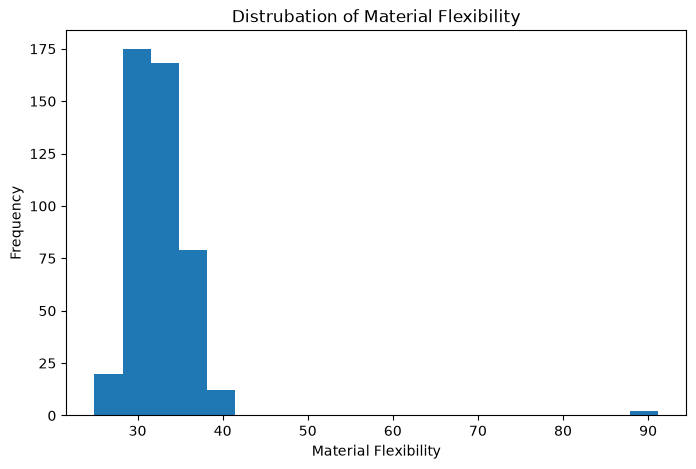

In [19]:
plt.figure(figsize=(8,5))
plt.hist(df["material_flexibility"].dropna(),bins=20)
plt.xlabel("Material Flexibility")
plt.ylabel("Frequency")
plt.title("Distrubation of Material Flexibility")

plt.show()

In [20]:
df["material_flexibility"].sort_values(ascending=False).head(10)

421    91.157913
9      91.157913
161    40.452981
143    40.165117
407    40.080371
79     39.429438
266    39.198270
308    38.925162
125    38.745914
63     38.388974
Name: material_flexibility, dtype: float64

In [21]:
df[df["material_flexibility"]>50]

,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,inspection_season,inspection_window,moisture_stress,failure
9,2,91.157913,12.004540,2.661193,55.022194,8.960423,4.858190,2.55912,winter,night,0.01,0
421,5,91.157913,12.053391,3.817170,64.528942,9.192685,4.953214,2.68840,winter,afternoon,0.01,0


In [22]:
Q1 = df["material_flexibility"].quantile(0.25)
Q3 = df["material_flexibility"].quantile(0.75)

IQR = Q3-Q1

lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


Q1: 30.496860786359775
Q3: 34.02675606249045
IQR: 3.5298952761306737
Lower limit: 25.202017872163765
Upper limit: 39.32159897668646


In [23]:
outliers = df[
    (df["material_flexibility"] < lower_limit) |
    (df["material_flexibility"] > upper_limit)
]

print("Number of potential outliers:", len(outliers))

display(outliers[["material_flexibility", "inspector_id"]])

Number of potential outliers: 7


,material_flexibility,inspector_id
9,91.157913,2
79,39.429438,4
143,40.165117,1
161,40.452981,7
193,24.924765,2
407,40.080371,7
421,91.157913,5


In [24]:
display(df.loc[[9,421]])

,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,inspection_season,inspection_window,moisture_stress,failure
9,2,91.157913,12.004540,2.661193,55.022194,8.960423,4.858190,2.55912,winter,night,0.01,0
421,5,91.157913,12.053391,3.817170,64.528942,9.192685,4.953214,2.68840,winter,afternoon,0.01,0


In [25]:
print(df["material_flexibility"].describe())

count    456.000000
mean      32.592037
std        4.738187
min       24.924765
25%       30.496861
50%       31.902116
75%       34.026756
max       91.157913
Name: material_flexibility, dtype: float64


In [26]:
df["material_flexibility"].sort_values().tail(15)

229    37.765980
374    38.181562
100    38.241189
350    38.270892
18     38.280777
63     38.388974
125    38.745914
308    38.925162
266    39.198270
79     39.429438
407    40.080371
143    40.165117
161    40.452981
9      91.157913
421    91.157913
Name: material_flexibility, dtype: float64

In [27]:
df["material_flexibility"].value_counts().head(10)

material_flexibility
30.404362    3
31.089204    3
29.878730    3
32.375998    3
30.944406    3
31.711469    3
31.762605    2
91.157913    2
33.820779    2
31.906319    2
Name: count, dtype: int64

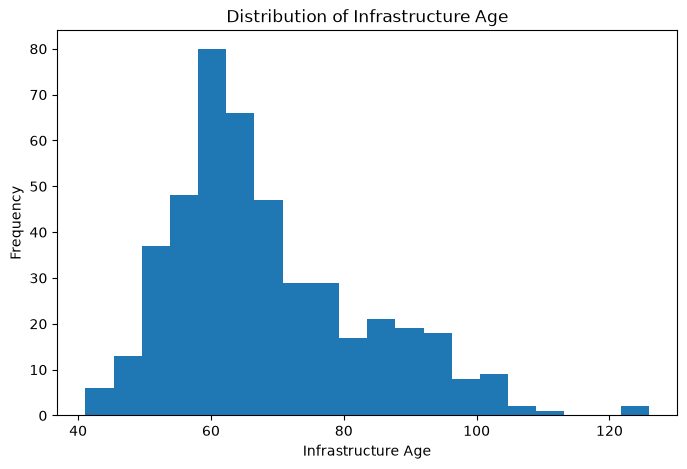

In [28]:
plt.figure(figsize=(8, 5))

plt.hist(df["infrastructure_age"].dropna(), bins=20)

plt.xlabel("Infrastructure Age")
plt.ylabel("Frequency")
plt.title("Distribution of Infrastructure Age")

plt.show()

In [29]:
df["infrastructure_age"].sort_values(
    ascending=False
).head(10)

143    125.949552
161    125.328825
125    109.106422
256    108.330895
118    106.036225
374    103.992028
134    103.579412
229    102.833271
63     102.131027
251    101.465941
Name: infrastructure_age, dtype: float64

In [30]:
Q1_age = df["infrastructure_age"].quantile(0.25)

Q3_age = df["infrastructure_age"].quantile(0.75)

IQR_age = Q3_age - Q1_age

upper_age = Q3_age + 1.5 * IQR_age

print("Q1:", Q1_age)
print("Q3:", Q3_age)
print("IQR:", IQR_age)
print("Upper limit:", upper_age)

Q1: 58.59449393992227
Q3: 76.73952227357182
IQR: 18.14502833364955
Upper limit: 103.95706477404615


I have searched for missing values and duplicate records in the dataset. There are 11 null values across five numeric columns, and no duplicate rows.

I also found two spelling mistakes: sumer and morni7ng in the categorical columns.

I plotted histograms of material_flexibility and infrastructure_age to see if there were any unusual values. I have used the IQR method to find out possible outliers in both the columns.

I decided to keep these values for now, as I was not able to verify that they were data-entry errors.

In [31]:
df_clean = df.copy()
print("originial dataset shape:", df.shape)
print("working dataset shape:",df_clean.shape)

originial dataset shape: (456, 12)
working dataset shape: (456, 12)


In [32]:
df_clean["inspection_season"] = (df_clean["inspection_season"].replace("sumer","summer"))

df_clean["inspection_window"] = (df_clean["inspection_window"].replace("morni7ng","morning"))

In [33]:
print(df_clean["inspection_season"].value_counts())
print()
print(df_clean["inspection_window"].value_counts())

inspection_season
summer    134
autumn    122
winter    115
spring     85
Name: count, dtype: int64

inspection_window
night        172
morning      149
afternoon    135
Name: count, dtype: int64


In [34]:
df_clean.isnull().sum()

inspector_id             0
material_flexibility     0
structural_mass_ratio    1
recent_precipitation     2
infrastructure_age       4
surface_debris           0
vibration_exposure       1
asset_density            0
inspection_season        0
inspection_window        0
moisture_stress          3
failure                  0
dtype: int64

In [35]:
numeric_columns = [
    "material_flexibility",
    "structural_mass_ratio",
    "recent_precipitation",
    "infrastructure_age",
    "surface_debris",
    "vibration_exposure",
    "asset_density",
    "moisture_stress"
]

print("Numerical columns", numeric_columns)

Numerical columns ['material_flexibility', 'structural_mass_ratio', 'recent_precipitation', 'infrastructure_age', 'surface_debris', 'vibration_exposure', 'asset_density', 'moisture_stress']


In [36]:
df_clean[numeric_columns].median()

material_flexibility     31.902116
structural_mass_ratio    11.863909
recent_precipitation      2.925396
infrastructure_age       64.789151
surface_debris            9.125281
vibration_exposure        4.960576
asset_density             2.595360
moisture_stress           0.020000
dtype: float64

I explored the missing values of the clean dataset and got eight numerical features for the modeling process. I have also calculated their medians. I'll use median imputation because it is less sensitive to extreme values than the mean. The imputation will be fitted only on the training data to prevent data leakage

In [37]:
X = df_clean.drop(columns=["failure","inspector_id"])
y = df_clean["failure"]
print("Features shape:",X.shape)
print("Target shape:",y.shape)

Features shape: (456, 10)
Target shape: (456,)


In [38]:
numeric_features = [
    "material_flexibility",
    "structural_mass_ratio",
    "recent_precipitation",
    "infrastructure_age",
    "surface_debris",
    "vibration_exposure",
    "asset_density",
    "moisture_stress"
]

categorical_features = [
    "inspection_season",
    "inspection_window"
]

print("Numerical features:",len(numeric_features))
print("Categorical features:",len(categorical_features))

Numerical features: 8
Categorical features: 2


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size = 0.4,
    random_state = 42,
    stratify = y
)

X_val,X_test,y_val,y_test = train_test_split(
    X_temp,
    y_temp,
    test_size = 0.5,
    random_state = 42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)



Training data: (273, 10)
Validation data: (91, 10)
Testing data: (92, 10)


In [40]:
print("Training target distribution")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution")
print(y_val.value_counts(normalize=True))

print("\nTesting target distribution")
print(y_test.value_counts(normalize=True))

Training target distribution
failure
0    0.630037
1    0.369963
Name: proportion, dtype: float64

Validation target distribution
failure
0    0.637363
1    0.362637
Name: proportion, dtype: float64

Testing target distribution
failure
0    0.630435
1    0.369565
Name: proportion, dtype: float64


I divided the dataset into three parts 60% for training, 20% for validation and 20% for testing. I used stratified sampling to keep the failure and non-failure proportions similar in all three sets. The training data will be used to build the models the validation data to compare and tune them and the test data to evalute the final model